# Project 20: Push Test Data Pipeline + Dashboard
Data simulasi. Notebook membaca CSV hasil pipeline; angka tidak dihitung ulang.

In [1]:
from pathlib import Path
import pandas as pd
R1 = Path('..') / '1-data-preparation'
R2 = Path('..') / '2-analysis'
rd = lambda n, d=R2: pd.read_csv(d / n)


## Q1 dan Q11: pemuatan file dan ground truth

In [2]:
print('ingest_attempts.csv'); display(rd('ingest_attempts.csv', R1))

ingest_attempts.csv


,percobaan,file_dibaca,loaded,quarantined,skipped
0,1,1214,1159,41,14
1,2,1214,0,0,1214


In [3]:
print('ground_truth_files.csv'); display(rd('ground_truth_files.csv', R2))

ground_truth_files.csv


,jenis,ditanam,terdeteksi,tidak_terdeteksi
0,format mesin baru,18,18,0
1,file terpotong (bukan format baru),23,23,0
2,file terpotong yang juga format baru,1,1,0
3,salinan ganda (nama copy_of_),14,14,0
4,format angka titik/koma lain (tidak rusak),36,36,0


In [4]:
print('ground_truth_normal.csv'); display(rd('ground_truth_normal.csv', R2))

ground_truth_normal.csv


,file_normal,file_normal_dimuat,file_normal_salah_karantina,file_rusak_ditanam,file_rusak_lolos_dimuat,file_dikarantina
0,1159,1159,0,41,0,41


## Q2 dan Q3: rekonsiliasi dengan proses lama

In [5]:
print('macro_summary.csv'); display(rd('macro_summary.csv', R2))

macro_summary.csv


,file_di_folder,file_macro_gagal_format_baru,file_terpotong_terbaca_sebagian,file_salinan_terbaca_dua_kali,nilai_pipeline,nilai_berubah,persen_nilai_berubah,file_terdampak,file_dimuat_pipeline,nilai_macro_total,nilai_macro_dari_salinan,nilai_macro_dari_file_terpotong,selisih_nilai_macro_vs_pipeline,rata_nilai_berubah_macro,rata_nilai_berubah_pipeline
0,1214,19,23,13,14476,436,0.030119,36,1159,14669,158,35,193,7.568402,7568.402294


In [6]:
print('macro_group_compare.csv'); display(rd('macro_group_compare.csv', R2))

macro_group_compare.csv


,model,condition,ukuran,pipeline,macro,selisih
0,Model A,after_oven,n,3531.000000,3578.000000,47.000000
1,Model A,after_oven,mean_g,8474.066468,8199.872680,-274.193788
2,Model A,after_oven,min_g,4823.100000,6.769100,-4816.330900
3,Model A,after_oven,max_g,11642.900000,11642.900000,0.000000
4,Model A,after_oven,cpk,2.580155,1.306171,-1.273984
5,Model A,after_oven,oos_rate,0.000000,0.030743,0.030743
6,Model A,before_oven,n,3854.000000,3936.000000,82.000000
7,Model A,before_oven,mean_g,7067.120161,6906.363159,-160.757002
8,Model A,before_oven,min_g,4068.800000,5.209000,-4063.591000
9,Model A,before_oven,max_g,10331.400000,10331.400000,0.000000


In [7]:
print('macro_session_compare.csv'); display(rd('macro_session_compare.csv', R2))

macro_session_compare.csv


,ukuran,sesi,sesi_beda,persen,selisih_abs_maks
0,mean,1159,36,0.031061,9495.2619
1,min,1159,36,0.031061,8265.2265
2,max,1159,36,0.031061,11148.3405


## Q4 dan Q5: Cpk dan out-of-spec

In [8]:
print('cpk_group.csv'); display(rd('cpk_group.csv', R2))

cpk_group.csv


,peringkat,model,condition,n,sesi,mean_g,sd_g,cpk,cpk_ci_low,cpk_ci_high,jarak_ke_lsl_sd,di_bawah_cpk_target,n_cukup,oos_n,oos_rate,oos_ci_low,oos_ci_high,batas_atas_aturan_tiga
0,1,Model B,before_oven,3507,282,6676.220388,884.731340,1.950204,1.902892,1.997125,5.850613,0,1,0,0,0,0.001094,0.000855
1,2,Model A,before_oven,3854,308,7067.120161,901.648526,2.058126,2.012348,2.105351,6.174379,0,1,0,0,0,0.000996,0.000778
2,3,Model B,after_oven,3584,287,8155.996261,906.530961,2.447424,2.387821,2.507275,7.342271,0,1,0,0,0,0.001071,0.000837
3,4,Model A,after_oven,3531,282,8474.066468,900.988093,2.580155,2.518015,2.646538,7.740465,0,1,0,0,0,0.001087,0.000850


In [9]:
print('kpi_group.csv'); display(rd('kpi_group.csv', R2))

kpi_group.csv


,model,condition,sesi,n,mean_g,min_g,max_g,sd_g,lsl_g,usl_g,cpu,cpl,cpk,oos_rate
0,Model A,after_oven,282,3531,8474.066468,4823.1,11642.9,900.988093,1500.0,19000.0,3.894219,2.580155,2.580155,0.0
1,Model A,before_oven,308,3854,7067.120161,4068.8,10331.4,901.648526,1500.0,19000.0,4.411505,2.058126,2.058126,0.0
2,Model B,after_oven,287,3584,8155.996261,5082.4,11388.2,906.530961,1500.0,19000.0,3.987363,2.447424,2.447424,0.0
3,Model B,before_oven,282,3507,6676.220388,3894.6,9606.9,884.731340,1500.0,19000.0,4.643134,1.950204,1.950204,0.0


## Q6 sampai Q8: shift, mesin, tren, pergeseran

In [10]:
print('shift_machine_test.csv'); display(rd('shift_machine_test.csv', R2))

shift_machine_test.csv


,faktor,kelompok_a,kelompok_b,sesi_a,sesi_b,median_resid_a,median_resid_b,selisih_rata_g,p_mannwhitney
0,shift,Shift 1,Shift 2,626,533,0.131960,51.667614,50.687748,2.639943e-02
1,machine_id,PT-01,PT-02,559,600,118.079257,-79.914156,-238.832300,1.736222e-24


In [11]:
print('weekly_all.csv'); display(rd('weekly_all.csv', R2))

weekly_all.csv


,iso_week,n,mean_g,sd_g,cpk,n_cukup
0,2026-W14,890,7721.131573,1149.933600,1.803331,1
1,2026-W15,1063,7718.063876,1143.890325,1.811964,1
2,2026-W16,1152,7717.454861,1120.918467,1.848917,1
3,2026-W17,1281,7578.171663,1134.906380,1.785220,1
4,2026-W18,1068,7683.176030,1107.850155,1.860413,1
5,2026-W19,938,7822.333156,1167.478568,1.805125,1
6,2026-W20,1225,7825.703510,1111.530252,1.896995,1
7,2026-W21,1023,7658.072825,1157.851123,1.772845,1
8,2026-W22,1170,7521.531709,1175.459745,1.707568,1
9,2026-W23,1018,7300.973576,1206.958164,1.602092,1


In [12]:
print('changepoint.csv'); display(rd('changepoint.csv', R2))

changepoint.csv


,machine_id,sesi,tanggal_titik_ubah,sesi_sebelum,sesi_sesudah,rata_sebelum_resid,rata_sesudah_resid,selisih_g,persen_dari_rata,t_welch,p_permutasi
0,PT-01,559,2026-06-02,395,164,133.024499,101.038914,-31.985584,-0.004147,1.138973,0.903654
1,PT-02,600,2026-05-23,350,250,144.511847,-478.776821,-623.288669,-0.083486,27.875843,0.003322


## Q9 dan Q10: waktu dihemat (estimated)

In [13]:
print('impact.csv'); display(rd('impact.csv', R2))

impact.csv


,menit_per_file,dasar,file_dimuat_periode,file_karantina_periode,file_per_tahun,menit_dihemat_per_file,menit_hemat_periode,jam_hemat_periode,jam_hemat_per_tahun,label
0,3,0,1159,41,4648.736264,3,3477,57.950000,232.436813,estimated
1,5,1,1159,41,4648.736264,5,5795,96.583333,387.394689,estimated
2,10,0,1159,41,4648.736264,10,11590,193.166667,774.789377,estimated


## Q12: idempoten dan tes

In [14]:
print('idempotency.csv'); display(rd('idempotency.csv', R2))

idempotency.csv


,tabel,setelah_percobaan_1,setelah_percobaan_2,tambahan
0,test_run,1159,1159,0
1,measurement,14476,14476,0
2,ingest_log,1214,2428,1214


In [15]:
print('pytest_result.csv'); display(rd('pytest_result.csv', R2))

pytest_result.csv


,tes,hasil
0,test_normal_file,lulus
1,test_thousand_separator_us_format,lulus
2,test_dot_thousand_comma_decimal,lulus
3,test_new_machine_format_goes_to_quarantine,lulus
4,test_empty_file,lulus
5,test_truncated_file,lulus
6,test_missing_header_field,lulus
7,test_non_numeric_value,lulus
8,test_out_of_range_values_flagged,lulus
9,test_duplicate_and_idempotent,lulus


## Cek silang dan lima fakta rancangan

In [16]:
print('crosscheck.csv'); display(rd('crosscheck.csv', R2))

crosscheck.csv


,cek,item,dibandingkan,cocok
0,SQL vs pandas (parser independen),per sesi: n,1159,1159
1,SQL vs pandas (parser independen),per sesi: mean_g,1159,1159
2,SQL vs pandas (parser independen),per sesi: min_g,1159,1159
3,SQL vs pandas (parser independen),per sesi: max_g,1159,1159
4,SQL vs pandas (parser independen),per sesi: sd_g,1159,1159
...,...,...,...,...
194,SQL vs Excel (LibreOffice),sesi PT-02_20260622_Shift1_ModelB_b: n,1,1
195,SQL vs Excel (LibreOffice),sesi PT-02_20260622_Shift1_ModelB_b: mean_g,1,1
196,SQL vs Excel (LibreOffice),sesi PT-02_20260622_Shift1_ModelB_b: min_g,1,1
197,SQL vs Excel (LibreOffice),sesi PT-02_20260622_Shift1_ModelB_b: max_g,1,1


In [17]:
print('design_facts.csv'); display(rd('design_facts.csv', R2))

design_facts.csv


,fakta,rancangan,ukuran,nilai,nilai2,keterangan
0,1,satu kombinasi dibuat bervariasi besar sehingg...,Cpk terendah,1.950204,0,"kombinasi di bawah 1,33"
1,2,rata-rata satu mesin turun sekitar 800 g selam...,selisih rata-rata mesin PT-02 setelah titik ub...,-623.288669,1,tanggal titik ubah sama dengan tanggal tertanam
2,3,sekitar 3% file berformat titik ribuan dan kom...,persen file dengan format angka lain,0.030000,36,file tertanam
3,4,"file bermasalah: header berbeda, kolom hilang,...",jenis file bermasalah tertanam,56.000000,14,file bermasalah tertanam (salinan)
4,5,"2% sampai 3% nilai tidak wajar (0, negatif, di...",hasil ukur tidak valid di data,0.000000,0,baris tidak valid


Rata-rata mingguan semua mesin

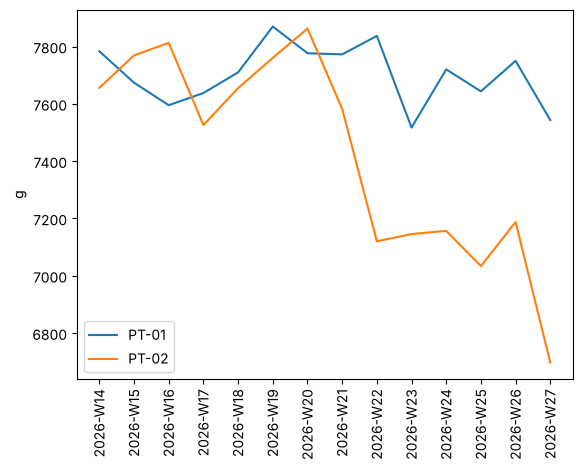

In [18]:
import matplotlib.pyplot as plt
d = rd('weekly_machine.csv'); [plt.plot(g.iso_week, g.mean_g, label=m) for m, g in d.groupby('machine_id')]
plt.xticks(rotation=90); plt.legend(); plt.ylabel('g'); plt.show()